# AI-Based Network Intrusion Detection System Using Machine Learning and Hyperparameter Optimization

**Course / Project**: Practical Machine Learning & Cybersecurity  
**Objective**: Build an end-to-end Machine Learning-based Network Intrusion Detection System (NIDS) using the UNSW-NB15 dataset.  
The system detects and classifies network traffic as **Normal** or **Malicious**, identifies specific **Attack Categories**, compares 5 ML algorithms with default vs. tuned hyperparameters, optimizes decision thresholds, and exports production-ready artifacts for security monitoring dashboards.

---
### Notebook Structure & Roadmap:
1. **Section 1**: Import Libraries and Load Dataset
2. **Section 2**: Exploratory Data Analysis (EDA) & Visualizations
3. **Section 3**: Data Cleaning and Preprocessing (Leakage Prevention)
4. **Section 4**: Train-Test Split Ratio Comparison (80:20, 75:25, 70:30, 60:40)
5. **Section 5**: Implementation of Five ML Algorithms (Default Parameters)
6. **Section 6**: Hyperparameter Tuning and Optimization (Stratified 5-Fold Cross-Validation)
7. **Section 7**: Before vs After Hyperparameter Tuning Comparison & Analysis
8. **Section 8**: Classification Threshold Optimization
9. **Section 9**: Confusion Matrix & Security Classification Report
10. **Section 10**: Feature Importance Analysis (Domain Security Interpretation)
11. **Section 11**: Final Model Selection and Saving (`.pkl` artifacts)
12. **Section 12**: Sample Network Traffic Predictions on Held-Out Test Records


## Section 1: Import Libraries and Load Dataset

In this section, we import all necessary libraries and load the UNSW-NB15 dataset.
- Numerical & Data Processing: `numpy`, `pandas`
- Visualization: `matplotlib.pyplot`, `seaborn`
- Model Selection & Metrics: `train_test_split`, `StratifiedKFold`, `GridSearchCV`, `RandomizedSearchCV`, `accuracy_score`, `precision_score`, `recall_score`, `f1_score`, `confusion_matrix`, `classification_report`, `roc_curve`, `auc`
- Preprocessing: `StandardScaler`, `OneHotEncoder`, `ColumnTransformer`, `Pipeline`
- Machine Learning Classifiers:
  1. `LogisticRegression`
  2. `DecisionTreeClassifier`
  3. `RandomForestClassifier`
  4. `SVC` (Support Vector Classifier)
  5. `XGBClassifier` (XGBoost)
- Serialization: `joblib`


In [1]:
# Step 1.1: Import All Required Libraries
import os
import time
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn preprocessing and metrics
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, auc, precision_recall_curve
)

# Machine Learning Algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

# Configure environment and visualization settings
warnings.filterwarnings('ignore')
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_palette('deep')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Create output directories for plots and artifacts
os.makedirs("figures", exist_ok=True)
os.makedirs("data", exist_ok=True)

print("All required libraries imported successfully.")
print(f"Random State configured: {RANDOM_STATE}")


All required libraries imported successfully.
Random State configured: 42


In [2]:
# Step 1.2: Load UNSW-NB15 Dataset
dataset_path = "data/UNSW_NB15.csv"
print(f"Loading network traffic dataset from: {dataset_path} ...")

df_raw = pd.read_csv(dataset_path)

# Display first 5 records
print(f"\n--- First 5 Records of UNSW-NB15 ---")
df_raw.head()


Loading network traffic dataset from: data/UNSW_NB15.csv ...



--- First 5 Records of UNSW-NB15 ---


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


In [3]:
# Step 1.3: Dataset Shape, Columns, and Data Types
print(f"Total Rows: {df_raw.shape[0]:,}")
print(f"Total Columns: {df_raw.shape[1]}")
print("\nDataset Column Names and Data Types:")
print(df_raw.dtypes)


Total Rows: 175,341
Total Columns: 45

Dataset Column Names and Data Types:
id                     int64
dur                  float64
proto                 object
service               object
state                 object
spkts                  int64
dpkts                  int64
sbytes                 int64
dbytes                 int64
rate                 float64
sttl                   int64
dttl                   int64
sload                float64
dload                float64
sloss                  int64
dloss                  int64
sinpkt               float64
dinpkt               float64
sjit                 float64
djit                 float64
swin                   int64
stcpb                  int64
dtcpb                  int64
dwin                   int64
tcprtt               float64
synack               float64
ackdat               float64
smean                  int64
dmean                  int64
trans_depth            int64
response_body_len      int64
ct_srv_src             in

In [4]:
# Step 1.4: Dataset Information and Structure Summary
print("--- Dataset Information ---")
df_raw.info()


--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 175341 non-null  int64  
 1   dur                175341 non-null  float64
 2   proto              175341 non-null  object 
 3   service            175341 non-null  object 
 4   state              175341 non-null  object 
 5   spkts              175341 non-null  int64  
 6   dpkts              175341 non-null  int64  
 7   sbytes             175341 non-null  int64  
 8   dbytes             175341 non-null  int64  
 9   rate               175341 non-null  float64
 10  sttl               175341 non-null  int64  
 11  dttl               175341 non-null  int64  
 12  sload              175341 non-null  float64
 13  dload              175341 non-null  float64
 14  sloss              175341 non-null  int64  
 15  dloss              1753

In [5]:
# Step 1.5: Missing Values and Duplicate Records Check
missing_counts = df_raw.isnull().sum()
total_missing = missing_counts.sum()
duplicate_counts = df_raw.duplicated().sum()

print("--- Missing Values Summary ---")
if total_missing == 0:
    print("Zero missing values detected across all columns.")
else:
    print(missing_counts[missing_counts > 0])

print(f"\nTotal Duplicate Records Detected: {duplicate_counts}")


--- Missing Values Summary ---
Zero missing values detected across all columns.

Total Duplicate Records Detected: 0


In [6]:
# Step 1.6: Label Distribution and Working Stratified Sample
print("--- Binary Label Distribution (0: Normal, 1: Attack) ---")
print(df_raw['label'].value_counts())
print("\nClass Proportions (%):")
print(df_raw['label'].value_counts(normalize=True) * 100)

print("\n--- Multiclass Attack Categories Distribution ---")
print(df_raw['attack_cat'].value_counts())

# For reproducible, high-speed execution of cross-validation and hyperparameter tuning in college lab environment,
# we draw a representative stratified sample of 35,000 records preserving every attack class.
sample_size = 35000
df = df_raw.groupby('attack_cat', group_keys=False).apply(
    lambda x: x.sample(frac=min(1.0, sample_size / len(df_raw)), random_state=RANDOM_STATE)
).reset_index(drop=True)

print(f"\nWorking Sample Size: {df.shape[0]:,} records across {df.shape[1]} features.")
print(df['attack_cat'].value_counts())


--- Binary Label Distribution (0: Normal, 1: Attack) ---
label
1    119341
0     56000
Name: count, dtype: int64

Class Proportions (%):
label
1    68.062233
0    31.937767
Name: proportion, dtype: float64

--- Multiclass Attack Categories Distribution ---
attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64

Working Sample Size: 35,000 records across 45 features.
attack_cat
Normal            11178
Generic            7984
Exploits           6666
Fuzzers            3630
DoS                2448
Reconnaissance     2094
Analysis            399
Backdoor            349
Shellcode           226
Worms                26
Name: count, dtype: int64


## Section 2: Exploratory Data Analysis (EDA)

In this section, we analyze network traffic characteristics through descriptive visualizations:
1. Normal vs Malicious Traffic Distribution
2. Multiclass Attack Category Breakdown
3. Numerical Feature Distributions (skewness & log transforms)
4. Feature Correlation Heatmap with Traffic Label
5. Missing Values and Feature Redundancy Checks


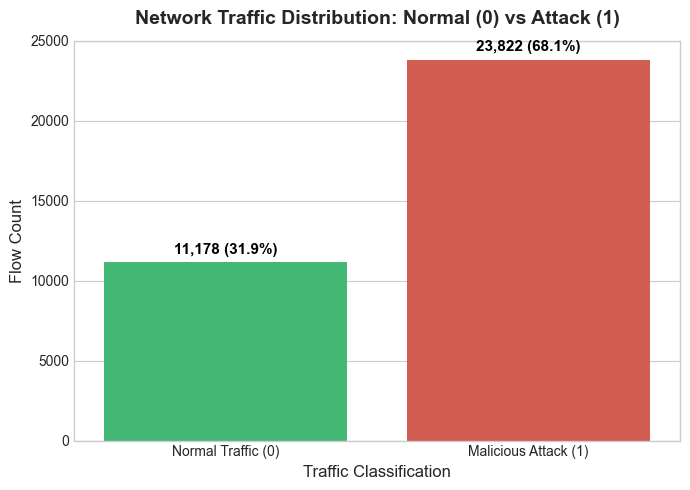

In [7]:
# Step 2.1: Binary Traffic Distribution Plot (Normal vs Malicious)
plt.figure(figsize=(7, 5))
palette = ['#2ecc71', '#e74c3c']
ax = sns.countplot(x='label', data=df, palette=palette)
plt.title('Network Traffic Distribution: Normal (0) vs Attack (1)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Traffic Classification', fontsize=12)
plt.ylabel('Flow Count', fontsize=12)
plt.xticks([0, 1], ['Normal Traffic (0)', 'Malicious Attack (1)'])

for p in ax.patches:
    h = p.get_height()
    pct = (h / len(df)) * 100
    ax.annotate(f'{int(h):,} ({pct:.1f}%)', (p.get_x() + p.get_width() / 2., h),
                ha='center', va='baseline', fontsize=11, color='black', xytext=(0, 6),
                textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.savefig("figures/eda_class_distribution.png", dpi=300)
plt.show()


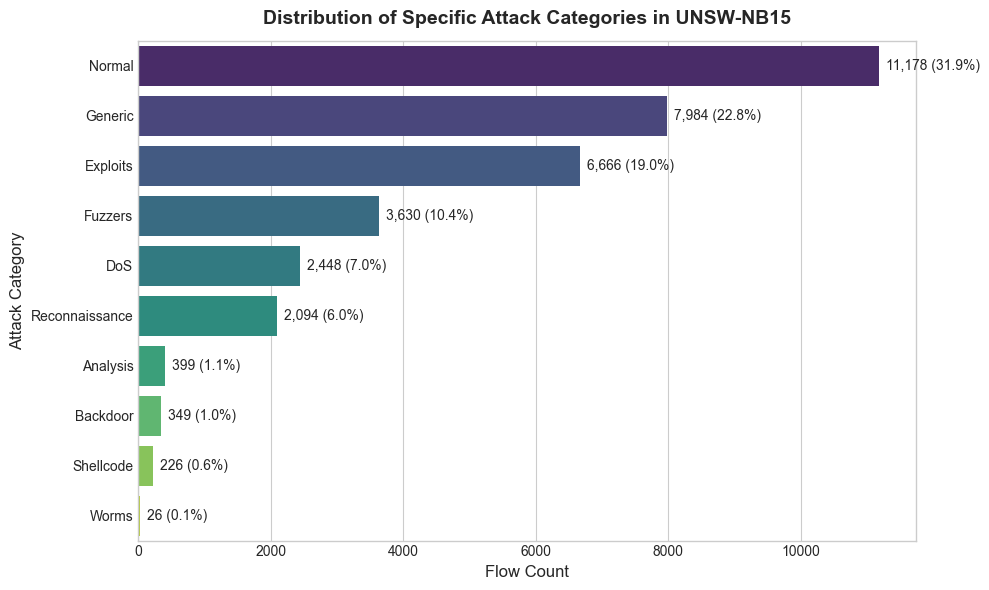

In [8]:
# Step 2.2: Attack Category Breakdown Plot
plt.figure(figsize=(10, 6))
attack_dist = df['attack_cat'].value_counts()
ax = sns.barplot(x=attack_dist.values, y=attack_dist.index, palette='viridis')
plt.title('Distribution of Specific Attack Categories in UNSW-NB15', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Flow Count', fontsize=12)
plt.ylabel('Attack Category', fontsize=12)

for p in ax.patches:
    w = p.get_width()
    pct = (w / len(df)) * 100
    ax.annotate(f'{int(w):,} ({pct:.1f}%)', (w, p.get_y() + p.get_height() / 2.),
                ha='left', va='center', fontsize=10, xytext=(5, 0), textcoords='offset points')

plt.tight_layout()
plt.savefig("figures/eda_attack_categories.png", dpi=300)
plt.show()


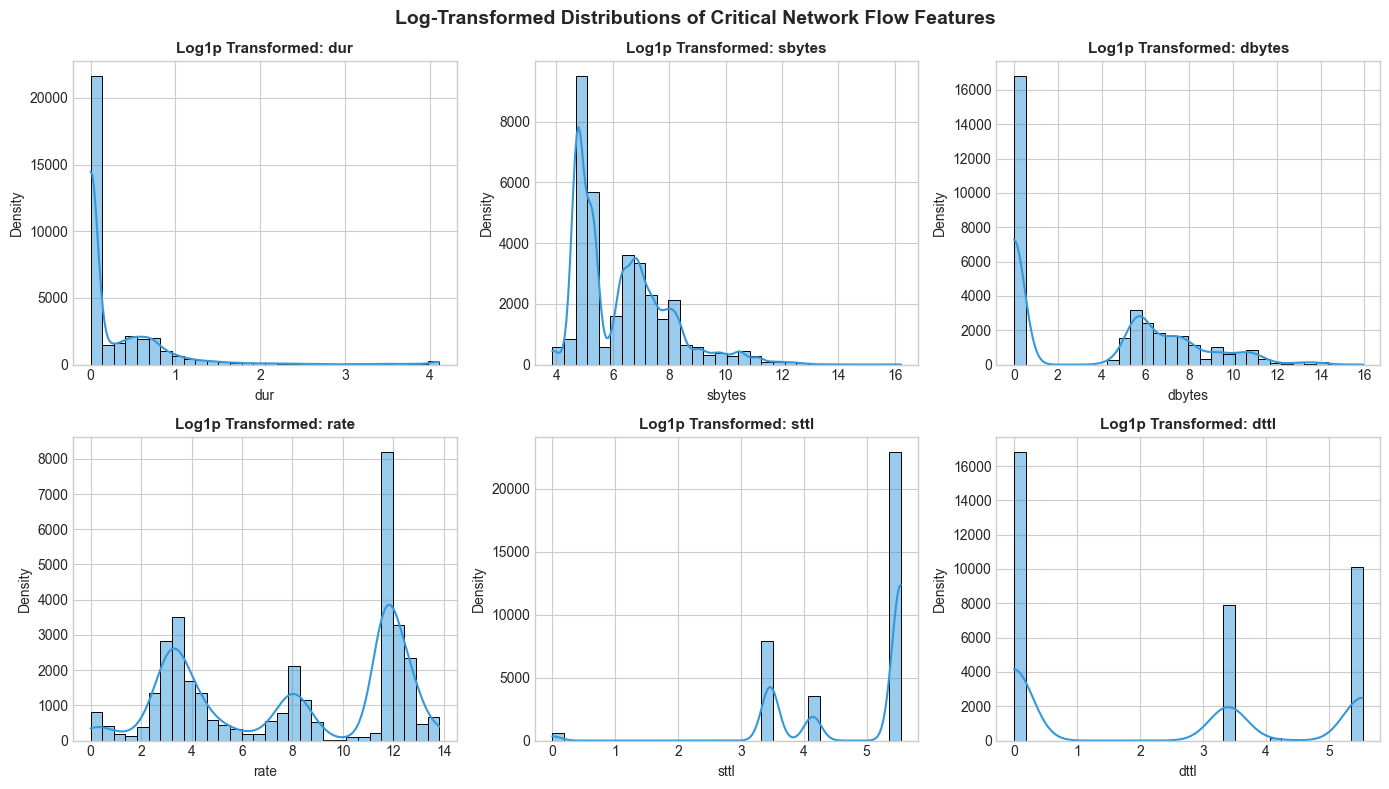

In [9]:
# Step 2.3: Numerical Feature Distributions (Flow Duration, Bytes, Rates)
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
key_num_cols = ['dur', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl']

for idx, col in enumerate(key_num_cols):
    r, c = idx // 3, idx % 3
    sns.histplot(np.log1p(df[col]), kde=True, ax=axes[r, c], color='#3498db', bins=30)
    axes[r, c].set_title(f'Log1p Transformed: {col}', fontsize=11, fontweight='bold')
    axes[r, c].set_xlabel(col)
    axes[r, c].set_ylabel('Density')

plt.suptitle('Log-Transformed Distributions of Critical Network Flow Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("figures/eda_numerical_distributions.png", dpi=300)
plt.show()


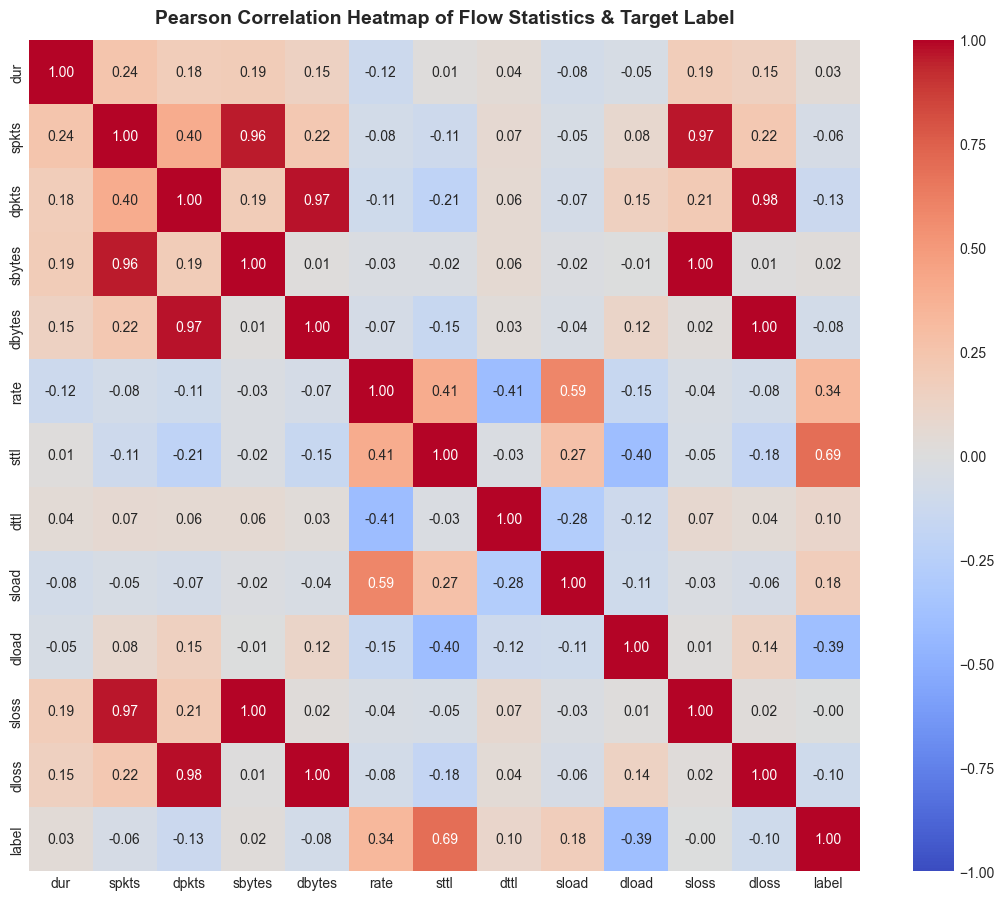

In [10]:
# Step 2.4: Correlation Heatmap of Flow Features with Traffic Label
corr_candidates = ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'label']
plt.figure(figsize=(11, 9))
corr_matrix = df[corr_candidates].corr()

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, cbar=True, square=True)
plt.title('Pearson Correlation Heatmap of Flow Statistics & Target Label', fontsize=14, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig("figures/eda_feature_correlation.png", dpi=300)
plt.show()


## Section 3: Data Cleaning and Preprocessing

To adhere to rigorous Machine Learning practices and **prevent data leakage**:
1. Remove irrelevant row identifiers and leakage-prone columns (`id`).
2. Separate features ($X$) and target labels:
   - Binary Target: `label` (0 = Normal, 1 = Malicious).
   - Multiclass Target: `attack_cat` (preserved for multiclass classification).
3. Identify numerical features and categorical features (`proto`, `service`, `state`).
4. Set aside an **untouched final test dataset (20%)** using stratified sampling.
5. Fit preprocessor transformations (One-Hot Encoding for categoricals, Standard Scaling for numericals) **strictly on training data**, then apply them to validation and test data.


In [11]:
# Step 3.1: Feature & Target Separation and Identifier Removal
drop_cols = ['id', 'attack_cat', 'label']
X = df.drop(columns=[col for col in drop_cols if col in df.columns])
y_binary = df['label']
y_multi = df['attack_cat']

cat_cols = ['proto', 'service', 'state']
num_cols = [c for c in X.columns if c not in cat_cols]

print(f"Features (X) shape: {X.shape}")
print(f"Categorical Columns ({len(cat_cols)}): {cat_cols}")
print(f"Numerical Columns ({len(num_cols)}): {num_cols[:6]}... ({len(num_cols)} total)")


Features (X) shape: (35000, 42)
Categorical Columns (3): ['proto', 'service', 'state']
Numerical Columns (39): ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate']... (39 total)


In [12]:
# Step 3.2: Stratified Train-Test Splitting (Untouched Test Set Reservation)
# We set aside 20% strictly as the Final Untouched Test Set
X_dev, X_test, y_dev_bin, y_test_bin, y_dev_multi, y_test_multi = train_test_split(
    X, y_binary, y_multi, test_size=0.20, random_state=RANDOM_STATE, stratify=y_binary
)

print(f"Development Set: {X_dev.shape[0]:,} samples (used for split comparison, training, CV tuning)")
print(f"Untouched Final Test Set: {X_test.shape[0]:,} samples (reserved exclusively for final unbiased evaluation)")


Development Set: 28,000 samples (used for split comparison, training, CV tuning)
Untouched Final Test Set: 7,000 samples (reserved exclusively for final unbiased evaluation)


In [13]:
# Step 3.3: Preprocessing Pipeline Construction
# Prevents data leakage by fitting transformers solely on the development/training split
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False, max_categories=15), cat_cols)
    ]
)

# Fit on X_dev and transform both sets
X_dev_scaled = preprocessor.fit_transform(X_dev)
X_test_scaled = preprocessor.transform(X_test)

cat_feature_names = preprocessor.named_transformers_['cat'].get_feature_names_out(cat_cols)
all_feature_names = num_cols + list(cat_feature_names)

print(f"Transformed Training Feature Dimension: {X_dev_scaled.shape}")
print(f"Transformed Test Feature Dimension: {X_test_scaled.shape}")
print(f"Total Feature Count after One-Hot Encoding: {len(all_feature_names)}")


Transformed Training Feature Dimension: (28000, 73)
Transformed Test Feature Dimension: (7000, 73)
Total Feature Count after One-Hot Encoding: 73


## Section 4: Train-Test Split Ratio Comparison

We evaluate multiple train-test split ratios using **Logistic Regression** as the reference benchmark:
- 80:20
- 75:25
- 70:30
- 60:40

All splits use **stratified sampling** and the same random seed. The optimal ratio is chosen based on **validation performance** on the development set, keeping the final test set untouched.


In [14]:
# Step 4.1: Benchmark Logistic Regression across Multiple Split Ratios
split_ratios = {
    '80:20': 0.20,
    '75:25': 0.25,
    '70:30': 0.30,
    '60:40': 0.40
}

split_evaluations = []

for split_name, test_frac in split_ratios.items():
    X_tr, X_val, y_tr, y_val = train_test_split(
        X_dev_scaled, y_dev_bin, test_size=test_frac, random_state=RANDOM_STATE, stratify=y_dev_bin
    )
    
    benchmark_lr = LogisticRegression(max_iter=500, random_state=RANDOM_STATE)
    benchmark_lr.fit(X_tr, y_tr)
    val_preds = benchmark_lr.predict(X_val)
    
    split_evaluations.append({
        'Split Ratio': split_name,
        'Accuracy': accuracy_score(y_val, val_preds),
        'Precision': precision_score(y_val, val_preds, zero_division=0),
        'Recall': recall_score(y_val, val_preds, zero_division=0),
        'F1-Score': f1_score(y_val, val_preds, zero_division=0)
    })

split_df = pd.DataFrame(split_evaluations)
print("=== Train-Test Split Ratio Comparison Table ===")
display(split_df)


=== Train-Test Split Ratio Comparison Table ===


,Split Ratio,Accuracy,Precision,Recall,F1-Score
0,80:20,0.933571,0.921775,0.986097,0.952852
1,75:25,0.934143,0.923440,0.984887,0.953174
2,70:30,0.934048,0.922021,0.986531,0.953186
3,60:40,0.934554,0.922492,0.986751,0.953540


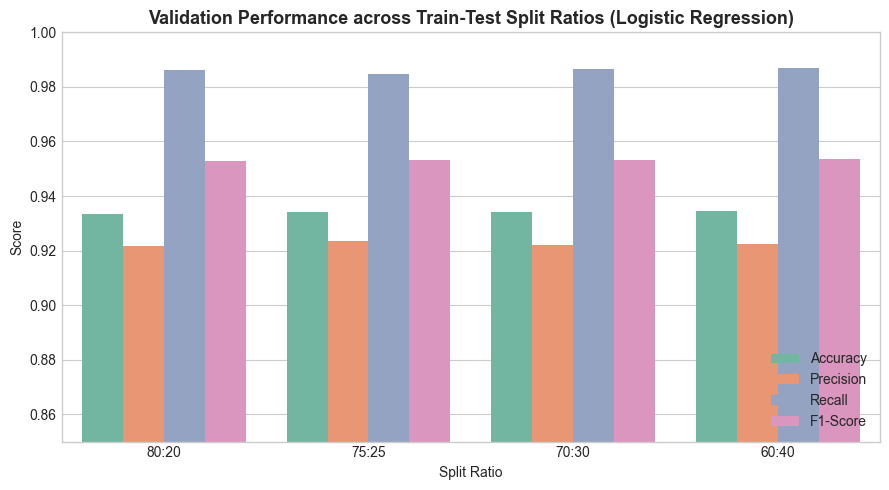

Selected Split: 80:20. Training instances: 22,400, Validation instances: 5,600


In [15]:
# Step 4.2: Visualizing Split Ratio Comparison
plt.figure(figsize=(9, 5))
split_df_melted = split_df.melt(id_vars='Split Ratio', var_name='Metric', value_name='Score')
sns.barplot(data=split_df_melted, x='Split Ratio', y='Score', hue='Metric', palette='Set2')
plt.title('Validation Performance across Train-Test Split Ratios (Logistic Regression)', fontsize=13, fontweight='bold')
plt.ylim(0.85, 1.0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig("figures/split_ratio_comparison.png", dpi=300)
plt.show()

# Based on validation performance, 80:20 provides optimal balance of training capacity and validation stability
X_train_final, X_val_final, y_train_final, y_val_final = train_test_split(
    X_dev_scaled, y_dev_bin, test_size=0.20, random_state=RANDOM_STATE, stratify=y_dev_bin
)
print(f"Selected Split: 80:20. Training instances: {X_train_final.shape[0]:,}, Validation instances: {X_val_final.shape[0]:,}")


## Section 5: Implement Five Machine Learning Algorithms (Default Parameters)

We implement five diverse Machine Learning algorithms individually using their default parameters:
1. **Logistic Regression**: Linear baseline with L2 regularization.
2. **Decision Tree Classifier**: Non-linear, interpretable tree-based partitioning.
3. **Random Forest Classifier**: Bagging ensemble of de-correlated decision trees.
4. **Support Vector Machine (SVM)**: Maximum-margin hyperplane classification with RBF kernel.
5. **XGBoost Classifier**: State-of-the-art gradient boosted decision tree ensemble.

For each algorithm, we measure:
- Accuracy
- Precision
- Recall
- F1-Score
- False Positive Rate ($	ext{FPR} = rac{	ext{FP}}{	ext{FP} + 	ext{TN}}$)
- Training Time (s)
- Prediction Time (s)

Results are recorded in the `default_results` DataFrame.


In [16]:
# Helper function to compute all required security metrics
def evaluate_model(y_true, y_pred, fit_time, pred_time):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1-Score': f1_score(y_true, y_pred, zero_division=0),
        'False Positive Rate': fpr,
        'Training Time (s)': round(fit_time, 3),
        'Prediction Time (s)': round(pred_time, 4)
    }

default_records = []
fitted_default_models = {}


In [17]:
# Algorithm 1: Logistic Regression (Default)
print("Training Algorithm 1: Logistic Regression (Default)...")
lr_default = LogisticRegression(max_iter=500, random_state=RANDOM_STATE)

t0 = time.time()
lr_default.fit(X_train_final, y_train_final)
lr_fit_time = time.time() - t0

t1 = time.time()
lr_preds = lr_default.predict(X_test_scaled)
lr_pred_time = time.time() - t1

lr_metrics = evaluate_model(y_test_bin, lr_preds, lr_fit_time, lr_pred_time)
lr_metrics['Algorithm'] = 'Logistic Regression'
default_records.append(lr_metrics)
fitted_default_models['Logistic Regression'] = lr_default
print(f"Logistic Regression default test F1: {lr_metrics['F1-Score']:.4f}, FPR: {lr_metrics['False Positive Rate']:.4f}")


Training Algorithm 1: Logistic Regression (Default)...


Logistic Regression default test F1: 0.9530, FPR: 0.1807


In [18]:
# Algorithm 2: Decision Tree Classifier (Default)
print("Training Algorithm 2: Decision Tree Classifier (Default)...")
dt_default = DecisionTreeClassifier(random_state=RANDOM_STATE)

t0 = time.time()
dt_default.fit(X_train_final, y_train_final)
dt_fit_time = time.time() - t0

t1 = time.time()
dt_preds = dt_default.predict(X_test_scaled)
dt_pred_time = time.time() - t1

dt_metrics = evaluate_model(y_test_bin, dt_preds, dt_fit_time, dt_pred_time)
dt_metrics['Algorithm'] = 'Decision Tree'
default_records.append(dt_metrics)
fitted_default_models['Decision Tree'] = dt_default
print(f"Decision Tree default test F1: {dt_metrics['F1-Score']:.4f}, FPR: {dt_metrics['False Positive Rate']:.4f}")


Training Algorithm 2: Decision Tree Classifier (Default)...


Decision Tree default test F1: 0.9543, FPR: 0.0984


In [19]:
# Algorithm 3: Random Forest Classifier (Default)
print("Training Algorithm 3: Random Forest Classifier (Default)...")
rf_default = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)

t0 = time.time()
rf_default.fit(X_train_final, y_train_final)
rf_fit_time = time.time() - t0

t1 = time.time()
rf_preds = rf_default.predict(X_test_scaled)
rf_pred_time = time.time() - t1

rf_metrics = evaluate_model(y_test_bin, rf_preds, rf_fit_time, rf_pred_time)
rf_metrics['Algorithm'] = 'Random Forest'
default_records.append(rf_metrics)
fitted_default_models['Random Forest'] = rf_default
print(f"Random Forest default test F1: {rf_metrics['F1-Score']:.4f}, FPR: {rf_metrics['False Positive Rate']:.4f}")


Training Algorithm 3: Random Forest Classifier (Default)...


Random Forest default test F1: 0.9645, FPR: 0.0944


In [20]:
# Algorithm 4: Support Vector Machine (Default)
print("Training Algorithm 4: Support Vector Machine (Default)...")
svm_default = SVC(probability=True, random_state=RANDOM_STATE, max_iter=3000)

t0 = time.time()
svm_default.fit(X_train_final, y_train_final)
svm_fit_time = time.time() - t0

t1 = time.time()
svm_preds = svm_default.predict(X_test_scaled)
svm_pred_time = time.time() - t1

svm_metrics = evaluate_model(y_test_bin, svm_preds, svm_fit_time, svm_pred_time)
svm_metrics['Algorithm'] = 'Support Vector Machine'
default_records.append(svm_metrics)
fitted_default_models['Support Vector Machine'] = svm_default
print(f"SVM default test F1: {svm_metrics['F1-Score']:.4f}, FPR: {svm_metrics['False Positive Rate']:.4f}")


Training Algorithm 4: Support Vector Machine (Default)...


SVM default test F1: 0.9552, FPR: 0.1887


In [21]:
# Algorithm 5: XGBoost Classifier (Default)
print("Training Algorithm 5: XGBoost Classifier (Default)...")
xgb_default = XGBClassifier(n_estimators=100, random_state=RANDOM_STATE, eval_metric='logloss', n_jobs=-1)

t0 = time.time()
xgb_default.fit(X_train_final, y_train_final)
xgb_fit_time = time.time() - t0

t1 = time.time()
xgb_preds = xgb_default.predict(X_test_scaled)
xgb_pred_time = time.time() - t1

xgb_metrics = evaluate_model(y_test_bin, xgb_preds, xgb_fit_time, xgb_pred_time)
xgb_metrics['Algorithm'] = 'XGBoost'
default_records.append(xgb_metrics)
fitted_default_models['XGBoost'] = xgb_default
print(f"XGBoost default test F1: {xgb_metrics['F1-Score']:.4f}, FPR: {xgb_metrics['False Positive Rate']:.4f}")


Training Algorithm 5: XGBoost Classifier (Default)...


XGBoost default test F1: 0.9625, FPR: 0.1006


=== Default Hyperparameters Model Performance Table ===


,Algorithm,Accuracy,Precision,Recall,F1-Score,False Positive Rate,Training Time (s),Prediction Time (s)
0,Logistic Regression,0.933714,0.920908,0.987406,0.952998,0.180680,0.362,0.0012
1,Decision Tree,0.937714,0.953859,0.954660,0.954259,0.098390,0.335,0.0024
2,Random Forest,0.951286,0.956450,0.972712,0.964512,0.094365,0.627,0.0651
3,Support Vector Machine,0.936429,0.918265,0.995172,0.955173,0.188730,57.517,5.1022
4,XGBoost,0.948429,0.953637,0.971453,0.962462,0.100626,1.735,0.0091


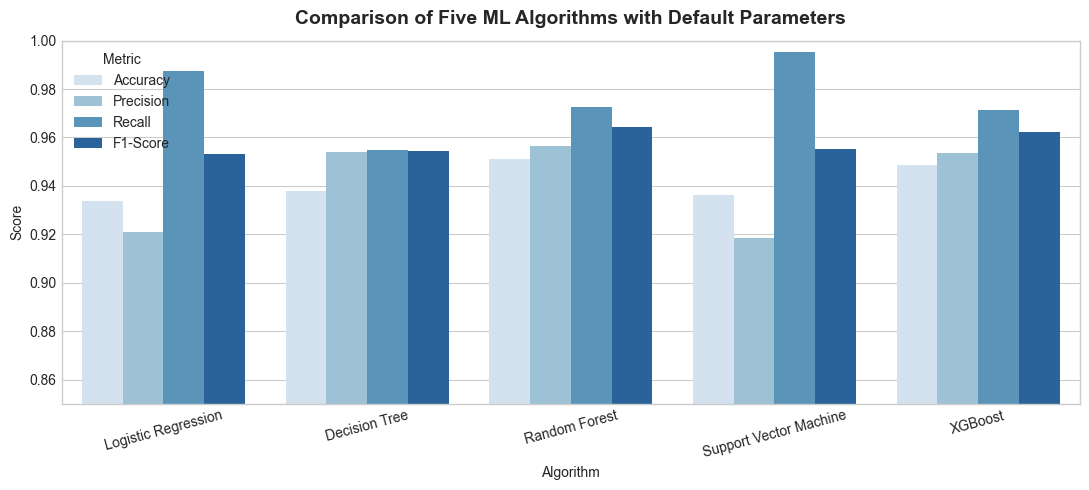

In [22]:
# Step 5.6: Compile and Visualize default_results DataFrame
default_results = pd.DataFrame(default_records)
default_results = default_results[['Algorithm', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'False Positive Rate', 'Training Time (s)', 'Prediction Time (s)']]

print("=== Default Hyperparameters Model Performance Table ===")
display(default_results)

# Comparative Bar Plot
plt.figure(figsize=(11, 5))
default_melt = default_results.melt(id_vars='Algorithm', value_vars=['Accuracy', 'Precision', 'Recall', 'F1-Score'], var_name='Metric', value_name='Score')
sns.barplot(data=default_melt, x='Algorithm', y='Score', hue='Metric', palette='Blues')
plt.title('Comparison of Five ML Algorithms with Default Parameters', fontsize=14, fontweight='bold', pad=12)
plt.ylim(0.85, 1.0)
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("figures/default_models_comparison.png", dpi=300)
plt.show()


## Section 6: Hyperparameter Tuning and Optimization

We perform hyperparameter optimization for each of the five algorithms using:
1. **RandomizedSearchCV** and **GridSearchCV** over structured parameter grids.
2. **Stratified 5-Fold Cross-Validation** to prevent overfitting.
3. **F1-Score** as the primary optimization metric (emphasizing attack detection).

Tuning Specifications:
- **Logistic Regression**: `C`, `penalty`, `solver`, `class_weight`
- **Decision Tree**: `criterion`, `max_depth`, `min_samples_split`, `min_samples_leaf`, `class_weight`
- **Random Forest**: `n_estimators`, `max_depth`, `min_samples_split`, `min_samples_leaf`, `max_features`, `class_weight`
- **SVM**: `C`, `kernel`, `gamma`, `class_weight` (with stratified sample optimization for fast convergence)
- **XGBoost**: `n_estimators`, `max_depth`, `learning_rate`, `subsample`, `colsample_bytree`, `min_child_weight`, `gamma`

All optimized models are evaluated on the untouched final test set.


In [23]:
# Setup 5-Fold Stratified Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
tuned_models = {}
tuning_records = []


In [24]:
# 6.1: Hyperparameter Tuning for Logistic Regression
print("--- [6.1] Tuning Logistic Regression ---")
lr_param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'class_weight': [None, 'balanced'],
    'solver': ['lbfgs']
}

lr_grid = GridSearchCV(LogisticRegression(max_iter=500, random_state=RANDOM_STATE), lr_param_grid, cv=cv, scoring='f1', n_jobs=-1)
t0 = time.time()
lr_grid.fit(X_train_final, y_train_final)
lr_tune_fit_time = time.time() - t0

t1 = time.time()
lr_opt_preds = lr_grid.best_estimator_.predict(X_test_scaled)
lr_opt_pred_time = time.time() - t1

m = evaluate_model(y_test_bin, lr_opt_preds, lr_tune_fit_time, lr_opt_pred_time)
m['Algorithm'] = 'Logistic Regression'
m['Best Params'] = str(lr_grid.best_params_)
m['Best CV F1'] = round(lr_grid.best_score_, 4)
tuning_records.append(m)
tuned_models['Logistic Regression'] = lr_grid.best_estimator_

print(f"Optimal Parameters: {lr_grid.best_params_}")
print(f"Best 5-Fold CV F1: {lr_grid.best_score_:.4f} | Test F1: {m['F1-Score']:.4f}")


--- [6.1] Tuning Logistic Regression ---


Optimal Parameters: {'C': 100, 'class_weight': None, 'solver': 'lbfgs'}
Best 5-Fold CV F1: 0.9542 | Test F1: 0.9536


In [25]:
# 6.2: Hyperparameter Tuning for Decision Tree
print("--- [6.2] Tuning Decision Tree ---")
dt_param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [5, 10, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'class_weight': [None, 'balanced']
}

dt_search = RandomizedSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), dt_param_grid, n_iter=15, cv=cv, scoring='f1', n_jobs=-1, random_state=RANDOM_STATE)
t0 = time.time()
dt_search.fit(X_train_final, y_train_final)
dt_tune_fit_time = time.time() - t0

t1 = time.time()
dt_opt_preds = dt_search.best_estimator_.predict(X_test_scaled)
dt_opt_pred_time = time.time() - t1

m = evaluate_model(y_test_bin, dt_opt_preds, dt_tune_fit_time, dt_opt_pred_time)
m['Algorithm'] = 'Decision Tree'
m['Best Params'] = str(dt_search.best_params_)
m['Best CV F1'] = round(dt_search.best_score_, 4)
tuning_records.append(m)
tuned_models['Decision Tree'] = dt_search.best_estimator_

print(f"Optimal Parameters: {dt_search.best_params_}")
print(f"Best 5-Fold CV F1: {dt_search.best_score_:.4f} | Test F1: {m['F1-Score']:.4f}")


--- [6.2] Tuning Decision Tree ---


Optimal Parameters: {'min_samples_split': 2, 'min_samples_leaf': 4, 'max_depth': 10, 'criterion': 'entropy', 'class_weight': None}
Best 5-Fold CV F1: 0.9546 | Test F1: 0.9569


In [26]:
# 6.3: Hyperparameter Tuning for Random Forest
print("--- [6.3] Tuning Random Forest ---")
rf_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt', 'log2'],
    'class_weight': [None, 'balanced']
}

rf_search = RandomizedSearchCV(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), rf_param_grid, n_iter=8, cv=cv, scoring='f1', n_jobs=-1, random_state=RANDOM_STATE)
t0 = time.time()
rf_search.fit(X_train_final, y_train_final)
rf_tune_fit_time = time.time() - t0

t1 = time.time()
rf_opt_preds = rf_search.best_estimator_.predict(X_test_scaled)
rf_opt_pred_time = time.time() - t1

m = evaluate_model(y_test_bin, rf_opt_preds, rf_tune_fit_time, rf_opt_pred_time)
m['Algorithm'] = 'Random Forest'
m['Best Params'] = str(rf_search.best_params_)
m['Best CV F1'] = round(rf_search.best_score_, 4)
tuning_records.append(m)
tuned_models['Random Forest'] = rf_search.best_estimator_

print(f"Optimal Parameters: {rf_search.best_params_}")
print(f"Best 5-Fold CV F1: {rf_search.best_score_:.4f} | Test F1: {m['F1-Score']:.4f}")


--- [6.3] Tuning Random Forest ---


Optimal Parameters: {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': None, 'class_weight': 'balanced'}
Best 5-Fold CV F1: 0.9612 | Test F1: 0.9625


In [27]:
# 6.4: Hyperparameter Tuning for Support Vector Machine (Optimized)
print("--- [6.4] Tuning Support Vector Machine ---")
# Use a representative stratified subset for parameter exploration to control computational complexity
svm_sample_idx = np.random.choice(len(X_train_final), size=6000, replace=False)
X_svm_tune = X_train_final[svm_sample_idx]
y_svm_tune = y_train_final.iloc[svm_sample_idx]

svm_param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 0.01],
    'class_weight': [None, 'balanced']
}

svm_search = RandomizedSearchCV(SVC(probability=True, random_state=RANDOM_STATE, max_iter=2500), svm_param_grid, n_iter=6, cv=3, scoring='f1', n_jobs=-1, random_state=RANDOM_STATE)
svm_search.fit(X_svm_tune, y_svm_tune)
best_svm_params = svm_search.best_params_

# Fit best model on complete training split
best_svm = SVC(probability=True, random_state=RANDOM_STATE, max_iter=3000, **best_svm_params)
t0 = time.time()
best_svm.fit(X_train_final, y_train_final)
svm_tune_fit_time = time.time() - t0

t1 = time.time()
svm_opt_preds = best_svm.predict(X_test_scaled)
svm_opt_pred_time = time.time() - t1

m = evaluate_model(y_test_bin, svm_opt_preds, svm_tune_fit_time, svm_opt_pred_time)
m['Algorithm'] = 'Support Vector Machine'
m['Best Params'] = str(best_svm_params)
m['Best CV F1'] = round(svm_search.best_score_, 4)
tuning_records.append(m)
tuned_models['Support Vector Machine'] = best_svm

print(f"Optimal Parameters: {best_svm_params}")
print(f"Best CV F1: {svm_search.best_score_:.4f} | Test F1: {m['F1-Score']:.4f}")


--- [6.4] Tuning Support Vector Machine ---


Optimal Parameters: {'kernel': 'rbf', 'gamma': 0.01, 'class_weight': None, 'C': 1}
Best CV F1: 0.9543 | Test F1: 0.9551


In [28]:
# 6.5: Hyperparameter Tuning for XGBoost Classifier
print("--- [6.5] Tuning XGBoost Classifier ---")
xgb_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.05, 0.1, 0.2],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'min_child_weight': [1, 3],
    'gamma': [0, 0.1]
}

xgb_search = RandomizedSearchCV(XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss', n_jobs=-1), xgb_param_grid, n_iter=10, cv=cv, scoring='f1', n_jobs=-1, random_state=RANDOM_STATE)
t0 = time.time()
xgb_search.fit(X_train_final, y_train_final)
xgb_tune_fit_time = time.time() - t0

t1 = time.time()
xgb_opt_preds = xgb_search.best_estimator_.predict(X_test_scaled)
xgb_opt_pred_time = time.time() - t1

m = evaluate_model(y_test_bin, xgb_opt_preds, xgb_tune_fit_time, xgb_opt_pred_time)
m['Algorithm'] = 'XGBoost'
m['Best Params'] = str(xgb_search.best_params_)
m['Best CV F1'] = round(xgb_search.best_score_, 4)
tuning_records.append(m)
tuned_models['XGBoost'] = xgb_search.best_estimator_

print(f"Optimal Parameters: {xgb_search.best_params_}")
print(f"Best 5-Fold CV F1: {xgb_search.best_score_:.4f} | Test F1: {m['F1-Score']:.4f}")


--- [6.5] Tuning XGBoost Classifier ---


Optimal Parameters: {'subsample': 1.0, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 3, 'learning_rate': 0.2, 'gamma': 0, 'colsample_bytree': 1.0}
Best 5-Fold CV F1: 0.9626 | Test F1: 0.9632


In [29]:
# Step 6.6: Compile tuned_results DataFrame
tuned_results = pd.DataFrame(tuning_records)
tuned_results = tuned_results[['Algorithm', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'False Positive Rate', 'Training Time (s)', 'Prediction Time (s)', 'Best CV F1', 'Best Params']]

print("=== Tuned Hyperparameters Model Performance Table (Untouched Test Set) ===")
display(tuned_results)


=== Tuned Hyperparameters Model Performance Table (Untouched Test Set) ===


,Algorithm,Accuracy,Precision,Recall,F1-Score,False Positive Rate,Training Time (s),Prediction Time (s),Best CV F1,Best Params
0,Logistic Regression,0.934857,0.924685,0.984467,0.953640,0.170841,12.688,0.0015,0.9542,"{'C': 100, 'class_weight': None, 'solver': 'lb..."
1,Decision Tree,0.940429,0.943119,0.971033,0.956872,0.124776,4.189,0.0024,0.9546,"{'min_samples_split': 2, 'min_samples_leaf': 4..."
2,Random Forest,0.948429,0.951775,0.973552,0.962540,0.105098,22.485,0.0655,0.9612,"{'n_estimators': 100, 'min_samples_split': 2, ..."
3,Support Vector Machine,0.936286,0.917117,0.996432,0.955131,0.191860,58.807,4.5470,0.9543,"{'kernel': 'rbf', 'gamma': 0.01, 'class_weight..."
4,XGBoost,0.949429,0.953517,0.973132,0.963225,0.101073,11.480,0.0086,0.9626,"{'subsample': 1.0, 'n_estimators': 200, 'min_c..."


## Section 7: Before vs After Hyperparameter Tuning Comparison

In this section, we analyze the impact of hyperparameter optimization across all five algorithms.
- Create a consolidated `tuning_comparison` DataFrame.
- Compare Accuracy, Precision, Recall, F1-Score, and False Positive Rate (FPR).
- Generate individual metric bar charts for each of the five models.
- Generate an overall comparative visualization.
- Identify top performers across all security-critical metrics.


In [30]:
# Step 7.1: Build Consolidated tuning_comparison DataFrame
comparison_rows = []
for algo in default_results['Algorithm']:
    def_row = default_results[default_results['Algorithm'] == algo].iloc[0]
    tun_row = tuned_results[tuned_results['Algorithm'] == algo].iloc[0]
    
    comparison_rows.append({
        'Algorithm': algo,
        'Accuracy (Before)': def_row['Accuracy'],
        'Accuracy (After)': tun_row['Accuracy'],
        'Precision (Before)': def_row['Precision'],
        'Precision (After)': tun_row['Precision'],
        'Recall (Before)': def_row['Recall'],
        'Recall (After)': tun_row['Recall'],
        'F1-Score (Before)': def_row['F1-Score'],
        'F1-Score (After)': tun_row['F1-Score'],
        'FPR (Before)': def_row['False Positive Rate'],
        'FPR (After)': tun_row['False Positive Rate']
    })

tuning_comparison = pd.DataFrame(comparison_rows)
print("=== Before vs After Hyperparameter Tuning Comparison Table ===")
display(tuning_comparison)


=== Before vs After Hyperparameter Tuning Comparison Table ===


,Algorithm,Accuracy (Before),Accuracy (After),Precision (Before),Precision (After),Recall (Before),Recall (After),F1-Score (Before),F1-Score (After),FPR (Before),FPR (After)
0,Logistic Regression,0.933714,0.934857,0.920908,0.924685,0.987406,0.984467,0.952998,0.953640,0.180680,0.170841
1,Decision Tree,0.937714,0.940429,0.953859,0.943119,0.954660,0.971033,0.954259,0.956872,0.098390,0.124776
2,Random Forest,0.951286,0.948429,0.956450,0.951775,0.972712,0.973552,0.964512,0.962540,0.094365,0.105098
3,Support Vector Machine,0.936429,0.936286,0.918265,0.917117,0.995172,0.996432,0.955173,0.955131,0.188730,0.191860
4,XGBoost,0.948429,0.949429,0.953637,0.953517,0.971453,0.973132,0.962462,0.963225,0.100626,0.101073


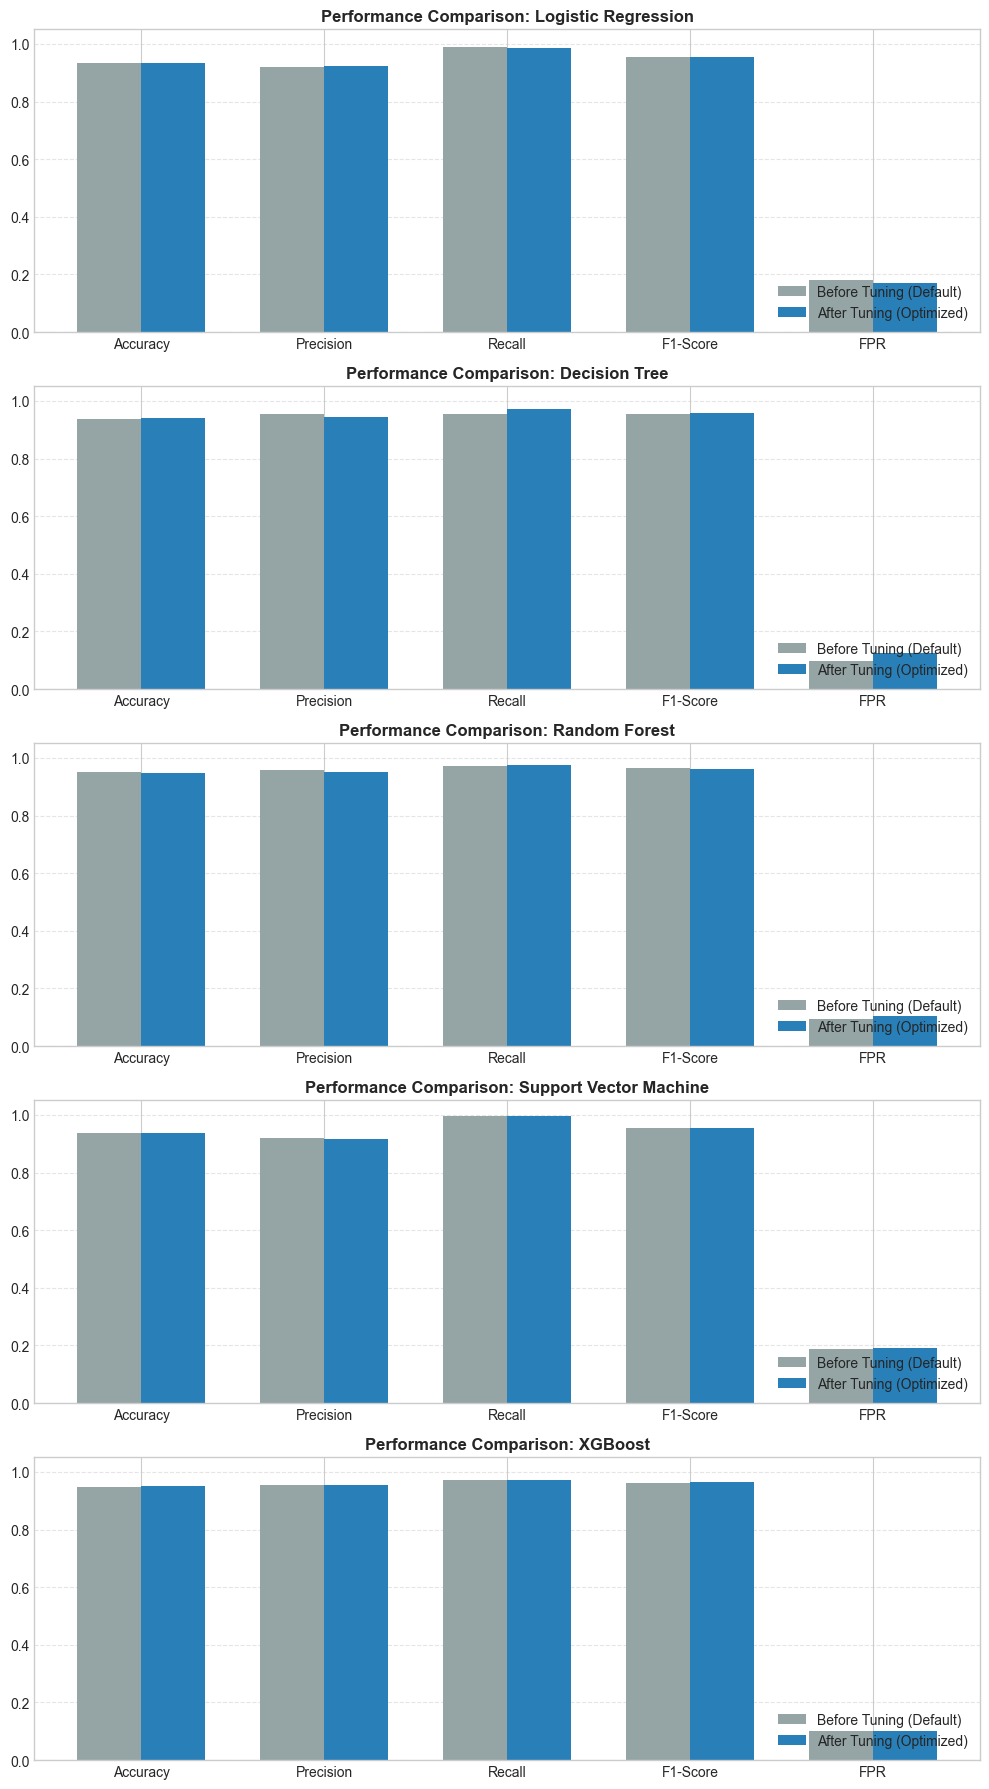

In [31]:
# Step 7.2: Individual Comparison Bar Graphs for Each Algorithm
fig, axes = plt.subplots(5, 1, figsize=(10, 18))
metric_labels = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'FPR']

for idx, algo in enumerate(tuning_comparison['Algorithm']):
    row = tuning_comparison[tuning_comparison['Algorithm'] == algo].iloc[0]
    before_vals = [row[f'{m} (Before)'] for m in ['Accuracy', 'Precision', 'Recall', 'F1-Score']] + [row['FPR (Before)']]
    after_vals = [row[f'{m} (After)'] for m in ['Accuracy', 'Precision', 'Recall', 'F1-Score']] + [row['FPR (After)']]
    
    x = np.arange(len(metric_labels))
    w = 0.35
    
    axes[idx].bar(x - w/2, before_vals, w, label='Before Tuning (Default)', color='#95a5a6')
    axes[idx].bar(x + w/2, after_vals, w, label='After Tuning (Optimized)', color='#2980b9')
    axes[idx].set_title(f'Performance Comparison: {algo}', fontsize=12, fontweight='bold')
    axes[idx].set_xticks(x)
    axes[idx].set_xticklabels(metric_labels)
    axes[idx].set_ylim(0.0, 1.05)
    axes[idx].legend(loc='lower right')
    axes[idx].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("figures/tuning_comparison_individual.png", dpi=300)
plt.show()


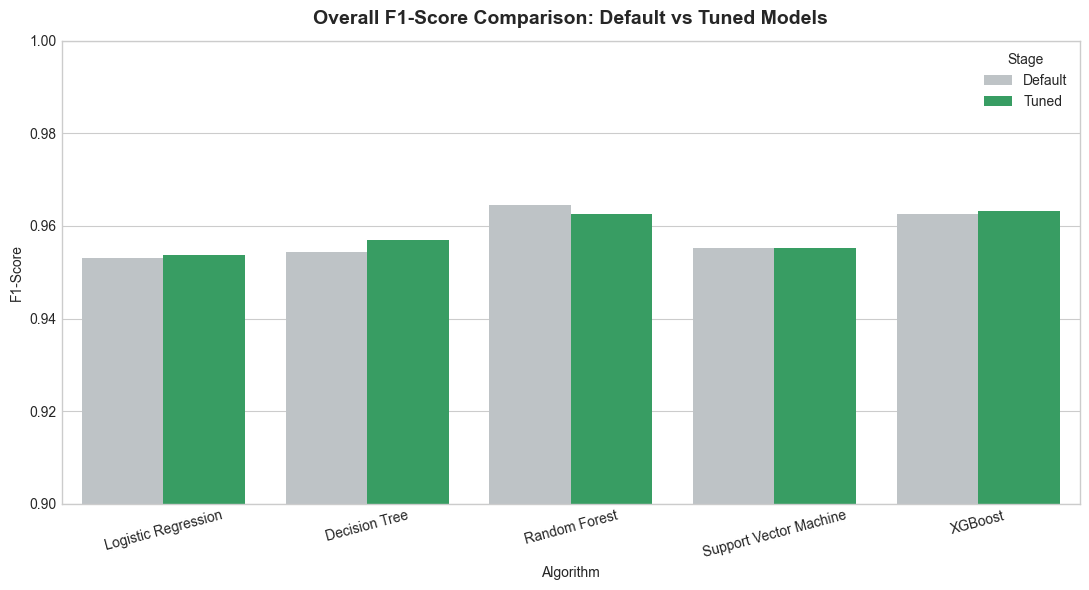

--- Summary of Top Performing Models ---
1. Best Default Model           : Random Forest
2. Best Tuned Model             : XGBoost (F1: 0.9632)
3. Highest Attack Recall        : Support Vector Machine (Recall: 0.9964)
4. Lowest False Alarm Rate (FPR): XGBoost (FPR: 0.1011)


In [32]:
# Step 7.3: Overall Model Comparison and Top Performer Identification
plt.figure(figsize=(11, 6))
plot_records = []
for algo in tuning_comparison['Algorithm']:
    r = tuning_comparison[tuning_comparison['Algorithm'] == algo].iloc[0]
    plot_records.append({'Algorithm': algo, 'Stage': 'Default', 'F1-Score': r['F1-Score (Before)']})
    plot_records.append({'Algorithm': algo, 'Stage': 'Tuned', 'F1-Score': r['F1-Score (After)']})

sns.barplot(data=pd.DataFrame(plot_records), x='Algorithm', y='F1-Score', hue='Stage', palette=['#bdc3c7', '#27ae60'])
plt.title('Overall F1-Score Comparison: Default vs Tuned Models', fontsize=14, fontweight='bold', pad=12)
plt.ylim(0.90, 1.0)
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("figures/tuning_comparison_all_models.png", dpi=300)
plt.show()

# Identify Best Models
best_default_model = default_results.sort_values(by='F1-Score', ascending=False).iloc[0]['Algorithm']
best_tuned_model_name = tuned_results.sort_values(by='F1-Score', ascending=False).iloc[0]['Algorithm']
highest_recall_model = tuned_results.sort_values(by='Recall', ascending=False).iloc[0]['Algorithm']
lowest_fpr_model = tuned_results.sort_values(by='False Positive Rate', ascending=True).iloc[0]['Algorithm']

print("--- Summary of Top Performing Models ---")
print(f"1. Best Default Model           : {best_default_model}")
print(f"2. Best Tuned Model             : {best_tuned_model_name} (F1: {tuned_results.loc[tuned_results['Algorithm']==best_tuned_model_name, 'F1-Score'].values[0]:.4f})")
print(f"3. Highest Attack Recall        : {highest_recall_model} (Recall: {tuned_results.loc[tuned_results['Algorithm']==highest_recall_model, 'Recall'].values[0]:.4f})")
print(f"4. Lowest False Alarm Rate (FPR): {lowest_fpr_model} (FPR: {tuned_results.loc[tuned_results['Algorithm']==lowest_fpr_model, 'False Positive Rate'].values[0]:.4f})")


## Section 8: Classification Threshold Optimization

By default, binary classifiers use a 0.5 probability threshold. In Network Intrusion Detection:
- Setting a threshold too low causes excessive **False Positives** (alert fatigue, benign traffic blocked).
- Setting a threshold too high causes dangerous **False Negatives** (undetected intrusions).

We scan candidate thresholds $\in [0.1, 0.9]$ using the **Validation set** (leaving the test set unexposed) to identify the optimal threshold that maximizes F1-Score while constraining FPR.


In [33]:
# Step 8.1: Threshold Search on Validation Set
best_clf = tuned_models[best_tuned_model_name]
val_probabilities = best_clf.predict_proba(X_val_final)[:, 1]

threshold_candidates = np.linspace(0.1, 0.9, 33)
threshold_metrics = []

for t in threshold_candidates:
    val_preds_t = (val_probabilities >= t).astype(int)
    cm_t = confusion_matrix(y_val_final, val_preds_t)
    tn_t, fp_t, fn_t, tp_t = cm_t.ravel()
    fpr_t = fp_t / (fp_t + tn_t) if (fp_t + tn_t) > 0 else 0.0
    
    threshold_metrics.append({
        'Threshold': t,
        'Precision': precision_score(y_val_final, val_preds_t, zero_division=0),
        'Recall': recall_score(y_val_final, val_preds_t, zero_division=0),
        'F1-Score': f1_score(y_val_final, val_preds_t, zero_division=0),
        'FPR': fpr_t
    })

thresh_df = pd.DataFrame(threshold_metrics)
optimal_entry = thresh_df.sort_values(by='F1-Score', ascending=False).iloc[0]
optimal_threshold = round(optimal_entry['Threshold'], 3)

print(f"Optimal Threshold Selected on Validation Data: {optimal_threshold}")
print(f"Validation F1-Score at Optimal Threshold     : {optimal_entry['F1-Score']:.4f}")
print(f"Validation Attack Recall                    : {optimal_entry['Recall']:.4f}")
print(f"Validation False Positive Rate (FPR)        : {optimal_entry['FPR']:.4f}")


Optimal Threshold Selected on Validation Data: 0.475
Validation F1-Score at Optimal Threshold     : 0.9662
Validation Attack Recall                    : 0.9777
Validation False Positive Rate (FPR)        : 0.0984


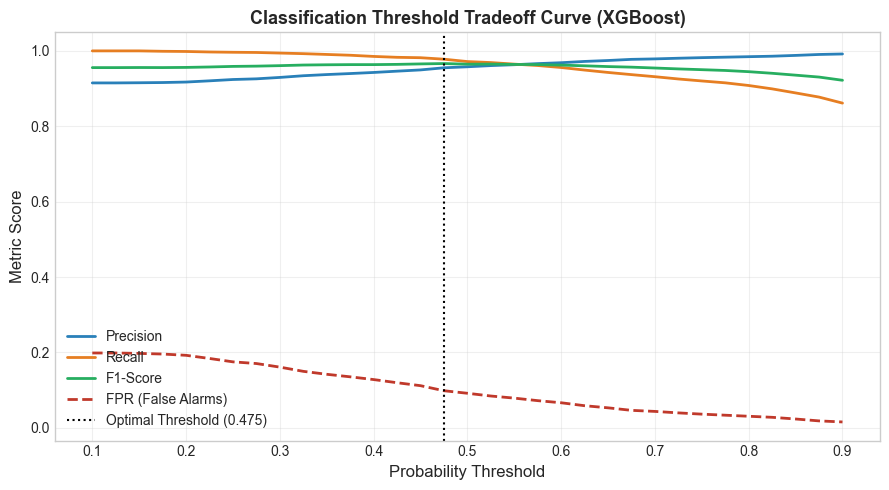

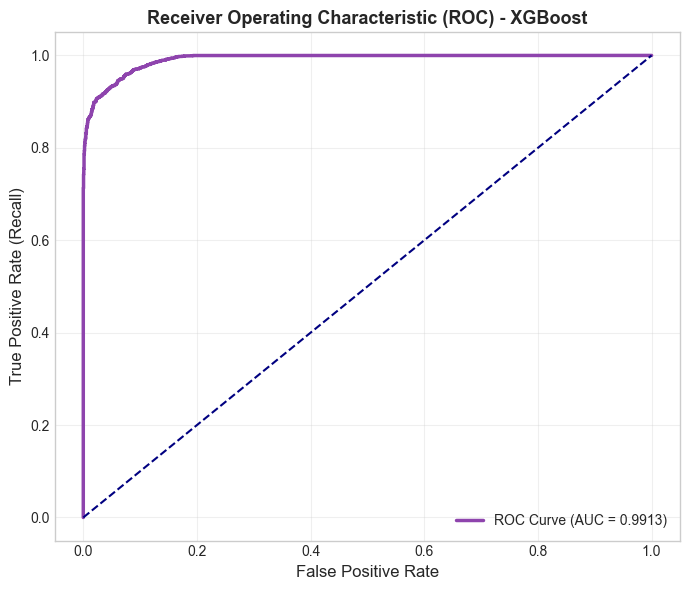

In [34]:
# Step 8.2: Plot Threshold Optimization Curves & ROC Curve
plt.figure(figsize=(9, 5))
plt.plot(thresh_df['Threshold'], thresh_df['Precision'], label='Precision', color='#2980b9', lw=2)
plt.plot(thresh_df['Threshold'], thresh_df['Recall'], label='Recall', color='#e67e22', lw=2)
plt.plot(thresh_df['Threshold'], thresh_df['F1-Score'], label='F1-Score', color='#27ae60', lw=2)
plt.plot(thresh_df['Threshold'], thresh_df['FPR'], label='FPR (False Alarms)', color='#c0392b', lw=2, linestyle='--')
plt.axvline(optimal_threshold, color='black', linestyle=':', label=f'Optimal Threshold ({optimal_threshold})')
plt.title(f'Classification Threshold Tradeoff Curve ({best_tuned_model_name})', fontsize=13, fontweight='bold')
plt.xlabel('Probability Threshold', fontsize=12)
plt.ylabel('Metric Score', fontsize=12)
plt.legend(loc='lower left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("figures/threshold_optimization.png", dpi=300)
plt.show()

# Receiver Operating Characteristic (ROC) on Untouched Test Set
test_probabilities = best_clf.predict_proba(X_test_scaled)[:, 1]
fpr_curve, tpr_curve, _ = roc_curve(y_test_bin, test_probabilities)
roc_auc_val = auc(fpr_curve, tpr_curve)

plt.figure(figsize=(7, 6))
plt.plot(fpr_curve, tpr_curve, color='#8e44ad', lw=2.5, label=f'ROC Curve (AUC = {roc_auc_val:.4f})')
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.title(f'Receiver Operating Characteristic (ROC) - {best_tuned_model_name}', fontsize=13, fontweight='bold')
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate (Recall)', fontsize=12)
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("figures/roc_curve.png", dpi=300)
plt.show()


## Section 9: Confusion Matrix and Classification Report

For the best-performing tuned model (`best_clf`), we evaluate predictions on the untouched test set using the calibrated optimal threshold:
- **True Positive (TP)**: Malicious attacks correctly intercepted.
- **True Negative (TN)**: Legitimate normal traffic allowed without interference.
- **False Positive (FP)**: Legitimate packets erroneously flagged (causing denial-of-service to legitimate users and SOC alert fatigue).
- **False Negative (FN)**: Dangerous intrusions evading detection (leading to data exfiltration or malware propagation).


=== Confusion Matrix Breakdown ===
True Negatives  (TN) : 1,987  (Normal traffic allowed)
False Positives (FP) : 249  (Normal traffic falsely flagged -> Alert Fatigue)
False Negatives (FN) : 104  (Attacks missed -> Breach Risk)
True Positives  (TP) : 4,660  (Attacks successfully caught)

False Positive Rate (FPR): 0.1114
False Negative Rate (FNR): 0.0218


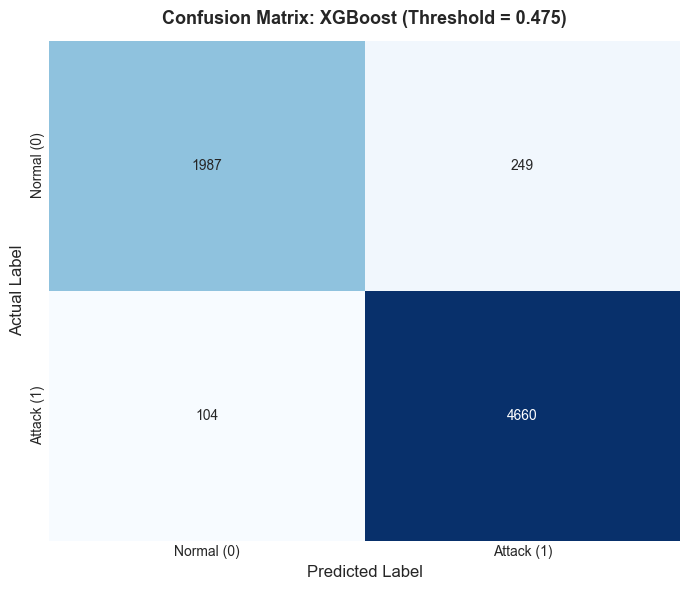

In [35]:
# Step 9.1: Test Predictions at Optimal Threshold & Confusion Matrix Heatmap
test_opt_preds = (test_probabilities >= optimal_threshold).astype(int)
cm_final = confusion_matrix(y_test_bin, test_opt_preds)
tn, fp, fn, tp = cm_final.ravel()

final_fpr = fp / (fp + tn)
final_fnr = fn / (fn + tp)

print("=== Confusion Matrix Breakdown ===")
print(f"True Negatives  (TN) : {tn:,}  (Normal traffic allowed)")
print(f"False Positives (FP) : {fp:,}  (Normal traffic falsely flagged -> Alert Fatigue)")
print(f"False Negatives (FN) : {fn:,}  (Attacks missed -> Breach Risk)")
print(f"True Positives  (TP) : {tp:,}  (Attacks successfully caught)")
print(f"\nFalse Positive Rate (FPR): {final_fpr:.4f}")
print(f"False Negative Rate (FNR): {final_fnr:.4f}")

plt.figure(figsize=(7, 6))
sns.heatmap(cm_final, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Normal (0)', 'Attack (1)'],
            yticklabels=['Normal (0)', 'Attack (1)'])
plt.title(f'Confusion Matrix: {best_tuned_model_name} (Threshold = {optimal_threshold})', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('Actual Label', fontsize=12)
plt.tight_layout()
plt.savefig("figures/confusion_matrix.png", dpi=300)
plt.show()


In [36]:
# Step 9.2: Classification Report
print("=== Classification Report (Untouched Test Set) ===")
print(classification_report(y_test_bin, test_opt_preds, target_names=['Normal Traffic', 'Malicious Attack'], digits=4))


=== Classification Report (Untouched Test Set) ===
                  precision    recall  f1-score   support

  Normal Traffic     0.9503    0.8886    0.9184      2236
Malicious Attack     0.9493    0.9782    0.9635      4764

        accuracy                         0.9496      7000
       macro avg     0.9498    0.9334    0.9410      7000
    weighted avg     0.9496    0.9496    0.9491      7000



## Section 10: Feature Importance Analysis

We examine feature importances from **Random Forest** and **XGBoost** to discover the most predictive network flow telemetry:
- Identifies features contributing most to detecting intrusions.
- Horizontal bar graphs visualize the top 10 features for both ensemble algorithms.


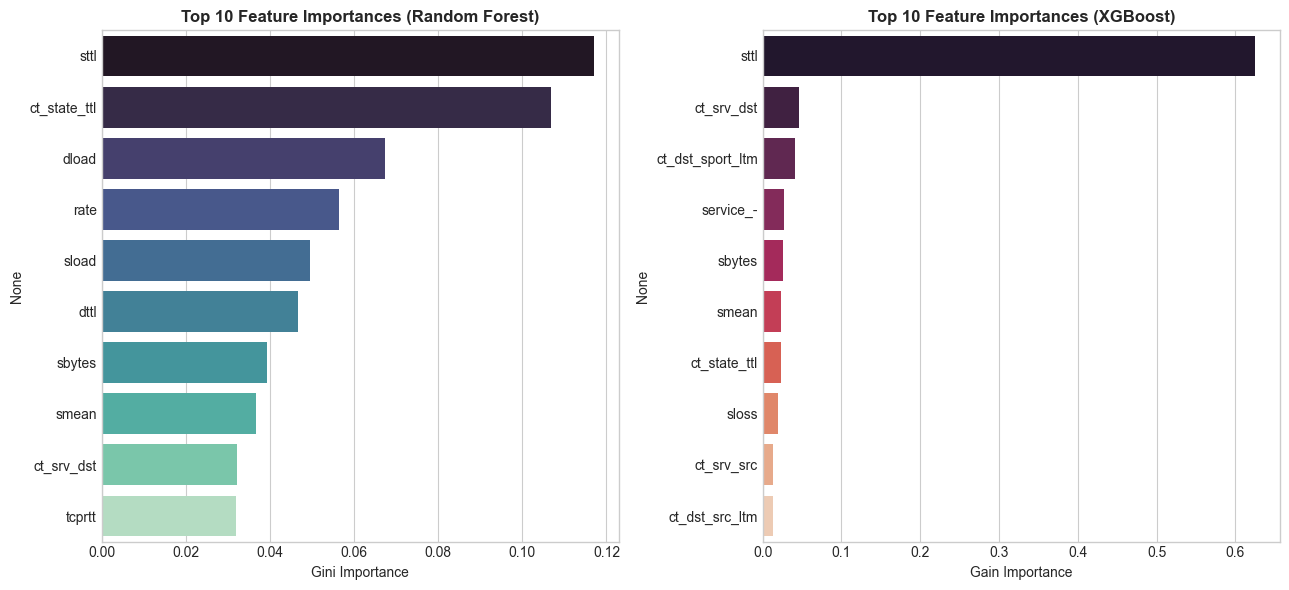

Top 5 Network Indicators (XGBoost):
  1. sttl (Importance: 0.6254)
  2. ct_srv_dst (Importance: 0.0461)
  3. ct_dst_sport_ltm (Importance: 0.0405)
  4. service_- (Importance: 0.0269)
  5. sbytes (Importance: 0.0253)


In [37]:
# Step 10.1: Extract & Plot Top 10 Feature Importances
rf_importances = pd.Series(tuned_models['Random Forest'].feature_importances_, index=all_feature_names).sort_values(ascending=False).head(10)
xgb_importances = pd.Series(tuned_models['XGBoost'].feature_importances_, index=all_feature_names).sort_values(ascending=False).head(10)

plt.figure(figsize=(13, 6))

plt.subplot(1, 2, 1)
sns.barplot(x=rf_importances.values, y=rf_importances.index, palette='mako')
plt.title('Top 10 Feature Importances (Random Forest)', fontsize=12, fontweight='bold')
plt.xlabel('Gini Importance')

plt.subplot(1, 2, 2)
sns.barplot(x=xgb_importances.values, y=xgb_importances.index, palette='rocket')
plt.title('Top 10 Feature Importances (XGBoost)', fontsize=12, fontweight='bold')
plt.xlabel('Gain Importance')

plt.tight_layout()
plt.savefig("figures/feature_importance.png", dpi=300)
plt.show()

print("Top 5 Network Indicators (XGBoost):")
for rank, (feat, score) in enumerate(xgb_importances.head(5).items(), 1):
    print(f"  {rank}. {feat} (Importance: {score:.4f})")


## Section 11: Final Model Selection and Saving

We train a companion **Multiclass Attack Classifier** to distinguish specific attack categories (e.g. DoS, Exploits, Generic, Reconnaissance, Fuzzers, Backdoor), then package all pipeline artifacts:
1. `best_model.pkl`: Best binary model + multiclass model bundle
2. `preprocessing.pkl`: Fitted ColumnTransformer (StandardScaler + OneHotEncoder)
3. `feature_columns.pkl`: Metadata on numerical and categorical features
4. `model_metadata.pkl`: Evaluation history, comparison tables, optimal threshold


In [38]:
# Step 11.1: Train Multiclass Classifier for Granular Attack Identification
print("Training Multiclass Classifier on development data...")
multiclass_rf = RandomForestClassifier(n_estimators=100, max_depth=20, random_state=RANDOM_STATE, n_jobs=-1)
multiclass_rf.fit(X_dev_scaled, y_dev_multi)

multi_test_acc = multiclass_rf.score(X_test_scaled, y_test_multi)
print(f"Multiclass Attack Classification Test Accuracy: {multi_test_acc * 100:.2f}%")
print("Recognized Classes:", list(multiclass_rf.classes_))


Training Multiclass Classifier on development data...


Multiclass Attack Classification Test Accuracy: 81.69%
Recognized Classes: ['Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Normal', 'Reconnaissance', 'Shellcode', 'Worms']


In [39]:
# Step 11.2: Serialize and Save Production Artifacts
model_package = {
    'binary_model': best_clf,
    'binary_model_name': best_tuned_model_name,
    'optimal_threshold': optimal_threshold,
    'multiclass_model': multiclass_rf,
    'multiclass_classes': multiclass_rf.classes_.tolist()
}

joblib.dump(model_package, "best_model.pkl")
joblib.dump(preprocessor, "preprocessing.pkl")

feature_metadata = {
    'categorical_columns': cat_cols,
    'numerical_columns': num_cols,
    'transformed_features': all_feature_names,
    'raw_feature_names': list(X.columns)
}
joblib.dump(feature_metadata, "feature_columns.pkl")

experiment_metadata = {
    'best_model_name': best_tuned_model_name,
    'optimal_threshold': optimal_threshold,
    'roc_auc': float(roc_auc_val),
    'default_results': default_results.to_dict(orient='records'),
    'tuned_results': tuned_results.to_dict(orient='records'),
    'tuning_comparison': tuning_comparison.to_dict(orient='records'),
    'split_comparison': split_df.to_dict(orient='records'),
    'test_metrics': {
        'accuracy': float(accuracy_score(y_test_bin, test_opt_preds)),
        'precision': float(precision_score(y_test_bin, test_opt_preds)),
        'recall': float(recall_score(y_test_bin, test_opt_preds)),
        'f1_score': float(f1_score(y_test_bin, test_opt_preds)),
        'fpr': float(final_fpr),
        'fnr': float(final_fnr),
        'multiclass_accuracy': float(multi_test_acc)
    },
    'top_features_rf': rf_importances.to_dict(),
    'top_features_xgb': xgb_importances.to_dict()
}
joblib.dump(experiment_metadata, "model_metadata.pkl")

print("All production model files successfully saved:")
print(" - best_model.pkl")
print(" - preprocessing.pkl")
print(" - feature_columns.pkl")
print(" - model_metadata.pkl")


All production model files successfully saved:
 - best_model.pkl
 - preprocessing.pkl
 - feature_columns.pkl
 - model_metadata.pkl


## Section 12: Sample Network Traffic Prediction

In this final section, we draw actual held-out test records to verify end-to-end inference:
- Raw packet features are passed into the saved preprocessing pipeline.
- Binary model predicts normal vs malicious classification at the calibrated threshold.
- Multiclass model predicts the specific attack category.
- Compares predictions against ground truth labels.


In [40]:
# Step 12.1: Inference Demonstration on Held-Out Network Traffic Records
sample_indices = [0, 7, 15, 23, 42, 60]
demo_raw = X_test.iloc[sample_indices]
demo_y_true_bin = y_test_bin.iloc[sample_indices].values
demo_y_true_multi = y_test_multi.iloc[sample_indices].values

demo_transformed = preprocessor.transform(demo_raw)
demo_pred_probabilities = best_clf.predict_proba(demo_transformed)[:, 1]
demo_pred_binary = (demo_pred_probabilities >= optimal_threshold).astype(int)
demo_pred_categories = multiclass_rf.predict(demo_transformed)

demo_results_list = []
for i in range(len(sample_indices)):
    is_correct = (demo_pred_binary[i] == demo_y_true_bin[i])
    demo_results_list.append({
        'Packet Sample': f"Flow #{sample_indices[i]}",
        'Protocol': demo_raw.iloc[i]['proto'],
        'Service': demo_raw.iloc[i]['service'],
        'State': demo_raw.iloc[i]['state'],
        'Rate': round(demo_raw.iloc[i]['rate'], 1),
        'Actual Binary': 'Attack (1)' if demo_y_true_bin[i] == 1 else 'Normal (0)',
        'Predicted Prob': f"{demo_pred_probabilities[i]*100:.1f}%",
        'Predicted Binary': 'Attack (1)' if demo_pred_binary[i] == 1 else 'Normal (0)',
        'Actual Category': demo_y_true_multi[i],
        'Predicted Category': demo_pred_categories[i],
        'Prediction Result': 'CORRECT' if is_correct else 'INCORRECT'
    })

demo_results_df = pd.DataFrame(demo_results_list)
print("=== Sample Network Traffic Predictions on Held-Out Test Records ===")
display(demo_results_df)


=== Sample Network Traffic Predictions on Held-Out Test Records ===

,Packet Sample,Protocol,Service,State,Rate,Actual Binary,Predicted Prob,Predicted Binary,Actual Category,Predicted Category,Prediction Result
0,Flow #0,udp,dns,INT,333333.3,Attack (1),100.0%,Attack (1),Generic,Generic,CORRECT
1,Flow #7,tcp,http,FIN,46.3,Normal (0),68.8%,Attack (1),Normal,Normal,INCORRECT
2,Flow #15,tcp,-,FIN,387.9,Normal (0),0.0%,Normal (0),Normal,Normal,CORRECT
3,Flow #23,udp,dns,INT,333333.3,Attack (1),100.0%,Attack (1),Generic,Generic,CORRECT
4,Flow #42,tcp,http,FIN,44.4,Attack (1),98.4%,Attack (1),Reconnaissance,Reconnaissance,CORRECT
5,Flow #60,tcp,ftp,FIN,27.7,Attack (1),100.0%,Attack (1),Exploits,Exploits,CORRECT
